# 09 — Correlação em primeira diferença

Extensão do passo 4 do roteiro de EDA (`docs/02_roteiro_eda.md`). O `06_correlacao.ipynb` calculou a matriz de correlação sobre os **níveis** das séries e já alertava que ela era só um "primeiro indício": câmbio, exportação e importação têm tendência de alta, e séries com tendência aparecem correlacionadas mesmo sem relação real (correlação espúria). O `07_estacionariedade.ipynb` confirmou que a maioria das séries precisa de **uma diferença** para ficar estacionária.

**Pergunta do notebook:** as correlações do `06` sobrevivem quando trocamos "quanto vale" por "quanto mudou desde o mês anterior"?

**Escolhas metodológicas:**

- **Recorte:** `painel_credito` (2015-01 a 2025-09), o mesmo do `06` e do `07`. Com a primeira diferença, ficam 128 observações mensais por série.
- **Transformação:** primeira diferença de todas as séries (`Δ = valor do mês − valor do mês anterior`). Para `credito_total`, a decisão entre nível e Δ está em aberto (ver `07`); aqui ela entra em Δ e a seção 3 testa a sensibilidade a essa escolha.
- **Medidas:** correlação de Pearson (relação linear, sensível a pontos extremos) e de Spearman (baseada em posições/ranks, muito menos sensível a pontos extremos).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy import stats
from IPython.display import display, Markdown

painel = pd.read_csv('https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/data/processed/painel_2015_2025.csv')
painel['data'] = pd.to_datetime(painel['ano'].astype(str) + '-' + painel['mes'].astype(str) + '-01')

# recorte decidido no 05_tratamento_nans.ipynb: 2015-01 a 2025-09, sem NaN nas colunas ESTBAN
painel_credito = painel[painel['data'] <= '2025-09-01'].copy()

series = ['cambio_venda', 'credito_total', 'exportação_fob', 'importação_fob', 'exportação_kg', 'importação_kg']
principais = ['cambio_venda', 'credito_total', 'exportação_fob', 'importação_fob']

niveis = painel_credito.set_index('data')[series]
dif = niveis.diff().dropna()
print(f"níveis: {len(niveis)} meses | primeira diferença: {len(dif)} meses, NaNs: {dif.isna().sum().sum()}")

def fmt(x, casas=2):
    """Número no formato brasileiro (vírgula decimal)."""
    x = round(x, casas)
    x = 0.0 if x == 0 else x  # evita "-0,00"
    return f"{x:.{casas}f}".replace('.', ',')

níveis: 129 meses | primeira diferença: 128 meses, NaNs: 0


## 1. Matriz de correlação: níveis vs primeira diferença

À esquerda, a matriz do `06` (níveis). À direita, a mesma matriz calculada sobre as diferenças. Mesma escala de cores nos dois painéis.

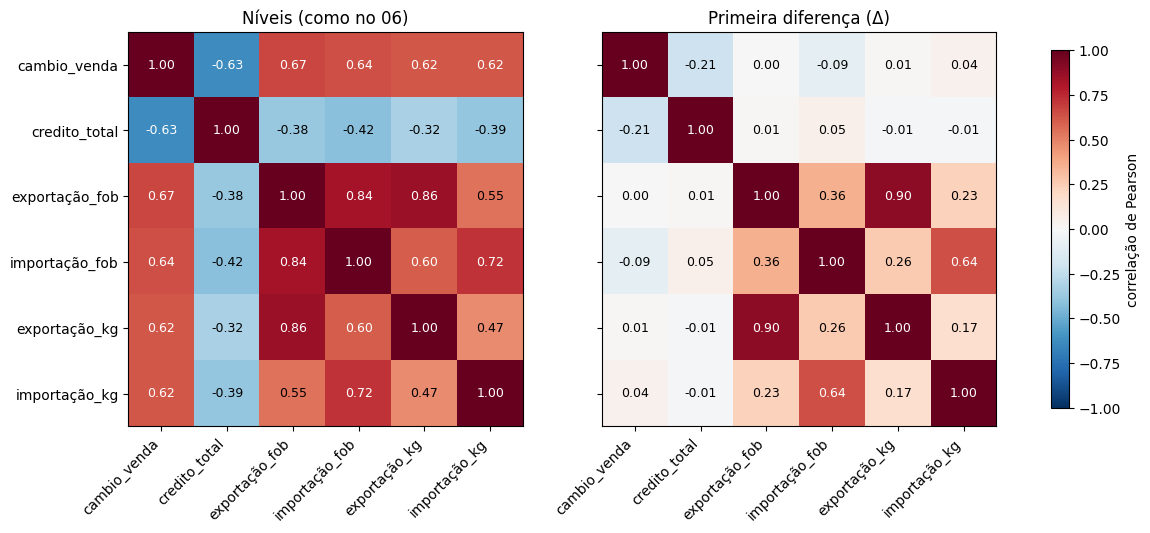

In [2]:
corr_niv = niveis.corr()
corr_dif = dif.corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), sharey=True)
for ax, corr, titulo in [(axes[0], corr_niv, 'Níveis (como no 06)'), (axes[1], corr_dif, 'Primeira diferença (Δ)')]:
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(len(series)))
    ax.set_yticks(range(len(series)))
    ax.set_xticklabels(series, rotation=45, ha='right')
    if ax is axes[0]:
        ax.set_yticklabels(series)
    for i in range(len(series)):
        for j in range(len(series)):
            v = corr.iloc[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if abs(v) > 0.6 else 'black', fontsize=9)
    ax.set_title(titulo)
fig.colorbar(im, ax=axes, shrink=0.8, label='correlação de Pearson')
plt.show()

In [3]:
linhas = []
for a, b in combinations(principais, 2):
    linhas.append(f"| `{a}` × `{b}` | {fmt(corr_niv.loc[a, b])} | {fmt(corr_dif.loc[a, b])} |")
display(Markdown('| par | correlação em nível | correlação em Δ |\n|---|---|---|\n' + '\n'.join(linhas)))

perda = np.mean([abs(corr_niv.loc[a, b]) - abs(corr_dif.loc[a, b]) for a, b in combinations(principais, 2)])
display(Markdown(f"Em média, o valor absoluto da correlação **cai {fmt(perda)}** ao passar de nível para Δ nos 6 pares das 4 variáveis principais."))

| par | correlação em nível | correlação em Δ |
|---|---|---|
| `cambio_venda` × `credito_total` | -0,63 | -0,21 |
| `cambio_venda` × `exportação_fob` | 0,67 | 0,00 |
| `cambio_venda` × `importação_fob` | 0,64 | -0,09 |
| `credito_total` × `exportação_fob` | -0,38 | 0,01 |
| `credito_total` × `importação_fob` | -0,42 | 0,05 |
| `exportação_fob` × `importação_fob` | 0,84 | 0,36 |

Em média, o valor absoluto da correlação **cai 0,48** ao passar de nível para Δ nos 6 pares das 4 variáveis principais.

## 2. Essas correlações em Δ são diferentes de zero?

Com 128 observações, uma correlação pequena pode aparecer só por acaso. O **p-valor** responde: *se a verdadeira correlação fosse zero, com que frequência eu veria uma correlação tão grande quanto a observada, só por sorte da amostra?* Quanto menor, mais difícil de atribuir ao acaso; o corte usual é 0,05.

Como aqui são **6 pares testados ao mesmo tempo**, a chance de pelo menos um dar "significativo" por sorte sobe. A correção de Bonferroni exige, para cada par, p < 0,05 ÷ 6 ≈ 0,0083.

In [4]:
alfa = 0.05
alfa_bonf = alfa / 6

linhas, resultados = [], {}
for a, b in combinations(principais, 2):
    r, p_r = stats.pearsonr(dif[a], dif[b])
    rho, p_rho = stats.spearmanr(dif[a], dif[b])
    resultados[(a, b)] = {'r': r, 'p_r': p_r, 'rho': rho, 'p_rho': p_rho}
    passa = 'sim' if p_r < alfa_bonf else 'não'
    linhas.append(f"| `{a}` × `{b}` | {fmt(r)} | {fmt(p_r, 4)} | {fmt(rho)} | {fmt(p_rho, 4)} | {passa} |")

display(Markdown('| par (em Δ) | Pearson r | p-valor | Spearman ρ | p-valor | passa Bonferroni? (Pearson) |\n|---|---|---|---|---|---|\n' + '\n'.join(linhas)))

| par (em Δ) | Pearson r | p-valor | Spearman ρ | p-valor | passa Bonferroni? (Pearson) |
|---|---|---|---|---|---|
| `cambio_venda` × `credito_total` | -0,21 | 0,0177 | -0,13 | 0,1324 | não |
| `cambio_venda` × `exportação_fob` | 0,00 | 0,9950 | 0,01 | 0,9038 | não |
| `cambio_venda` × `importação_fob` | -0,09 | 0,3059 | -0,06 | 0,4908 | não |
| `credito_total` × `exportação_fob` | 0,01 | 0,9043 | -0,07 | 0,4411 | não |
| `credito_total` × `importação_fob` | 0,05 | 0,5983 | 0,04 | 0,6396 | não |
| `exportação_fob` × `importação_fob` | 0,36 | 0,0000 | 0,30 | 0,0005 | sim |

## 3. Sensibilidade: o `credito_total` tem um degrau dominante

Como visto no `07`, a série diferenciada de `credito_total` tem **um ponto extremo** (o degrau de agosto/2019). Um único ponto assim pode criar, ou esconder, uma correlação de Pearson. Três checagens:

- **Sem o mês extremo:** recalcular a correlação removendo esse mês.
- **Spearman:** já calculado acima; usa posições, então um ponto extremo pesa muito menos.
- **Crédito em nível:** se o `credito_total` for tratado como estacionária no nível (como o ADF apontou), ele pode ser correlacionado com as **diferenças** das outras séries, sem diferenciar o próprio crédito.

In [5]:
cred = 'credito_total'
z = (dif[cred] - dif[cred].mean()) / dif[cred].std()
dt_ext = z.abs().idxmax()
dif_sem = dif.drop(dt_ext)
cred_nivel = niveis[cred].loc[dif.index]

linhas = []
sens = {}
for o in ['cambio_venda', 'exportação_fob', 'importação_fob']:
    r_todos = dif[cred].corr(dif[o])
    r_sem = dif_sem[cred].corr(dif_sem[o])
    rho = stats.spearmanr(dif[cred], dif[o])[0]
    r_niv = cred_nivel.corr(dif[o])
    sens[o] = {'todos': r_todos, 'sem': r_sem, 'rho': rho, 'niv': r_niv}
    linhas.append(f"| `{o}` | {fmt(r_todos)} | {fmt(r_sem)} | {fmt(rho)} | {fmt(r_niv)} |")

display(Markdown(
    f"Mês extremo removido: **{dt_ext.strftime('%Y-%m')}** (|z| = {fmt(abs(z.loc[dt_ext]), 1)}).\n\n"
    "| `credito_total` × | Pearson (Δ, todos os meses) | Pearson (Δ, sem o mês extremo) | Spearman (Δ) | Pearson (crédito em nível × Δ da outra) |\n"
    "|---|---|---|---|---|\n" + '\n'.join(linhas)
))

Mês extremo removido: **2019-08** (|z| = 6,1).

| `credito_total` × | Pearson (Δ, todos os meses) | Pearson (Δ, sem o mês extremo) | Spearman (Δ) | Pearson (crédito em nível × Δ da outra) |
|---|---|---|---|---|
| `cambio_venda` | -0,21 | -0,15 | -0,13 | -0,09 |
| `exportação_fob` | 0,01 | 0,00 | -0,07 | 0,00 |
| `importação_fob` | 0,05 | 0,06 | 0,04 | 0,06 |

## 4. E se a relação for defasada?

A correlação acima compara o **mesmo mês** nas duas séries. Um efeito do câmbio sobre o crédito ou o comércio pode levar meses para aparecer. A **correlação cruzada** compara a variação do câmbio no mês *t* com a variação da outra série no mês *t + k*:

- **k > 0:** a outra série reage ao câmbio *k* meses depois (o câmbio "vem antes").
- **k < 0:** a variação da outra série vem antes da do câmbio.
- **k = 0:** a correlação simultânea já vista.

A faixa tracejada é a referência de "sem correlação": ±2/√n (aprox. 95% dos valores ficariam dentro dela se as séries fossem independentes). Como são muitos lags testados, **alguns cruzamentos da faixa por acaso são esperados** (cerca de 5%).

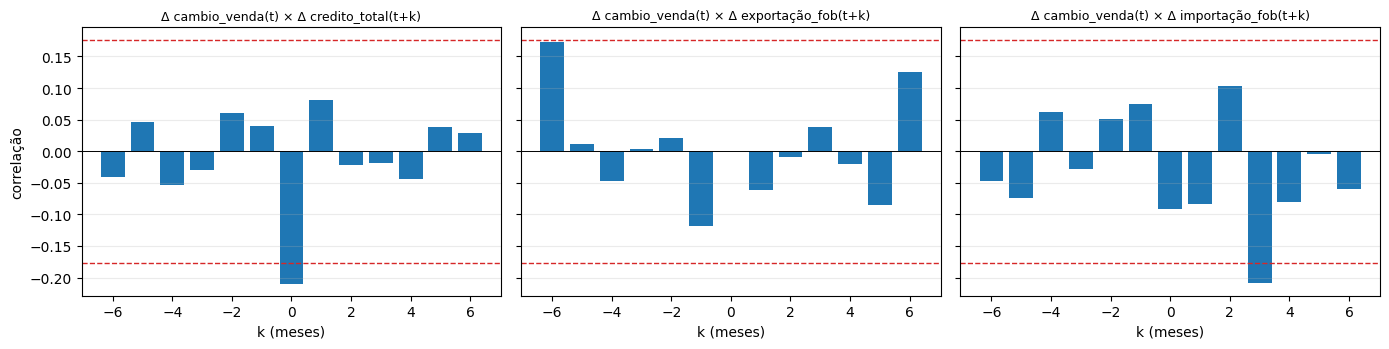

Correlações fora da faixa (±0,18): **2 de 39** testadas; por acaso, seriam esperadas cerca de 2,0.

- `credito_total` com k = 0: -0,21
- `importação_fob` com k = 3: -0,21

In [6]:
lags = range(-6, 7)
outras = ['credito_total', 'exportação_fob', 'importação_fob']
ccf = {o: [dif['cambio_venda'].corr(dif[o].shift(-k)) for k in lags] for o in outras}
faixa = 2 / np.sqrt(len(dif))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, o in zip(axes, outras):
    ax.bar(list(lags), ccf[o], color='tab:blue')
    ax.axhline(faixa, color='tab:red', linestyle='--', linewidth=1)
    ax.axhline(-faixa, color='tab:red', linestyle='--', linewidth=1)
    ax.axhline(0, color='black', linewidth=0.7)
    ax.set_title(f'Δ cambio_venda(t) × Δ {o}(t+k)', fontsize=9)
    ax.set_xlabel('k (meses)')
    ax.grid(alpha=0.25, axis='y')
axes[0].set_ylabel('correlação')
plt.tight_layout()
plt.show()

fora = [(o, k, v) for o in outras for k, v in zip(lags, ccf[o]) if abs(v) > faixa]
total = len(outras) * len(list(lags))
texto = f"Correlações fora da faixa (±{fmt(faixa)}): **{len(fora)} de {total}** testadas; por acaso, seriam esperadas cerca de {fmt(0.05 * total, 1)}.\n\n"
if fora:
    texto += '\n'.join(f"- `{o}` com k = {k}: {fmt(v)}" for o, k, v in fora)
display(Markdown(texto))

## 5. O que essa análise não mostra

- **Correlação de diferenças mede movimentos mensais parecidos**, não relação de longo prazo. Se duas séries I(1) compartilhassem uma tendência estocástica comum (**cointegração**), diferenciar apagaria justamente essa informação, e a correlação em Δ pareceria zero mesmo com relação real de longo prazo. Testar cointegração pertence à fase de modelagem, não a esta análise exploratória.
- **Correlação zero em Δ não prova ausência de relação:** a relação pode ser não linear, defasada em mais de 6 meses, restrita a períodos específicos (como 2020) ou aparecer só em frequência anual.
- **Correlação não é causalidade** em nenhum sentido; testes formais de precedência temporal (Granger) também ficam para a fase de modelagem.
- **O câmbio do painel é o de fechamento do mês**, então variações dentro do mês ficam invisíveis.

## Resumo

In [7]:
surv = [(a, b) for (a, b), v in resultados.items() if v['p_r'] < alfa_bonf]
niv = {(a, b): corr_niv.loc[a, b] for a, b in combinations(principais, 2)}

texto = "- Correlação de Pearson recalculada em primeira diferença (128 meses, `painel_credito`), sobre as 4 variáveis principais.\n"
texto += (f"- Em nível, `cambio_venda` correlacionava {fmt(niv[('cambio_venda', 'exportação_fob')])} com `exportação_fob` e {fmt(niv[('cambio_venda', 'importação_fob')])} com `importação_fob`. "
          f"Em Δ, esses valores passam a {fmt(resultados[('cambio_venda', 'exportação_fob')]['r'])} e {fmt(resultados[('cambio_venda', 'importação_fob')]['r'])}.\n")
texto += (f"- `cambio_venda` × `credito_total`: {fmt(niv[('cambio_venda', 'credito_total')])} em nível e {fmt(resultados[('cambio_venda', 'credito_total')]['r'])} em Δ "
          f"(p = {fmt(resultados[('cambio_venda', 'credito_total')]['p_r'], 4)}); sem o mês extremo, {fmt(sens['cambio_venda']['sem'])}; Spearman, {fmt(sens['cambio_venda']['rho'])} "
          f"(p = {fmt(resultados[('cambio_venda', 'credito_total')]['p_rho'], 4)}).\n")
if surv:
    texto += "- Pares que passam no corte de Bonferroni (Pearson, Δ): " + ', '.join(f"`{a}` × `{b}` (r = {fmt(resultados[(a, b)]['r'])})" for a, b in surv) + ".\n"
else:
    texto += "- Nenhum par passa no corte de Bonferroni.\n"
texto += f"- Correlação cruzada (lags de -6 a +6): {len(fora)} de {total} correlações fora da faixa de ±{fmt(faixa)}, contra ~{fmt(0.05 * total, 1)} esperadas por acaso.\n"
display(Markdown(texto))

- Correlação de Pearson recalculada em primeira diferença (128 meses, `painel_credito`), sobre as 4 variáveis principais.
- Em nível, `cambio_venda` correlacionava 0,67 com `exportação_fob` e 0,64 com `importação_fob`. Em Δ, esses valores passam a 0,00 e -0,09.
- `cambio_venda` × `credito_total`: -0,63 em nível e -0,21 em Δ (p = 0,0177); sem o mês extremo, -0,15; Spearman, -0,13 (p = 0,1324).
- Pares que passam no corte de Bonferroni (Pearson, Δ): `exportação_fob` × `importação_fob` (r = 0,36).
- Correlação cruzada (lags de -6 a +6): 2 de 39 correlações fora da faixa de ±0,18, contra ~2,0 esperadas por acaso.


**Leitura de conjunto:** as correlações fortes entre câmbio, exportação e importação em nível do `06` praticamente desaparecem em primeira diferença, o que confirma a suspeita levantada lá: eram, em boa parte, efeito de tendência compartilhada. O que sobra em Δ é pequeno (ver a tabela da seção 2). O par que mais se mantém é `exportação_fob` × `importação_fob`; uma hipótese possível é que os dois fluxos compartilhem fatores comuns do calendário, como o número de dias úteis do mês, mas isso é hipótese e não foi testado aqui. Leia também os limites da seção 5 antes de concluir qualquer coisa sobre relação entre as variáveis.

**Próximos passos (fora do roteiro de EDA):** planejar a fase de modelagem (cointegração e Granger, que exigem o tratamento de séries I(1) visto no `07`) e a fase de contexto (perguntas em aberto sobre 2020 e sobre o degrau de agosto/2019 do `credito_total`).